# 01 · Preprocessing — Bischoff 2021 LUAD (malignant compartment)

Lung adenocarcinoma (LUAD), 10x, 20 samples (10 tumor + 10 paired normal tissue). Isolate malignant
cells, derive a per-sample cell threshold by gap-finding, select over-dispersed genes, PCA, Harmony on
`sample`, embed, and **judge Gate 1**: is the malignant structure *both* sample-mixed and continuous?

**Gate 1 is judged on the regenerated embedding across an integration-strength sweep with a
per-neighborhood mixing metric — never a scalar alone** (evaluation lesson 1; the attempt-1 failure here
was passing a two-blob manifold as continuous on a `kNN connected-components = 1` scalar). We (i) sweep
Harmony `theta` × `n_pcs` to settle whether the two-lobe structure is under-integration or real biology,
(ii) settle each lobe's identity **before** the gate call (biology before geometry), and (iii) measure
continuity on the graph and diffusion axis, not a single scalar.

In [1]:
import os, sys, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import pearsonr, gaussian_kde
from scipy.signal import argrelextrema
import warnings, logging; warnings.filterwarnings('ignore'); logging.disable(logging.INFO)
sc.settings.verbosity = 0
np.random.seed(0)

### Paths — notebook runs in place (Category partition, two levels deeper than Puram)

In [3]:
# the '-1' testing suffix is stripped to resolve the raw data folder
cwd = os.getcwd()
name = os.path.split(cwd)[1]                        # Bischoff2021_Lung-1
category = os.path.split(os.path.split(cwd)[0])[1]  # Lung
raw_name = re.sub(r'-\d+$', '', name)               # Bischoff2021_Lung
pth = os.path.join('..', '..', '..', '..')   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{raw_name}')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
sys.path.append(os.path.join(pth, 'mesencontext', 'scripts'))
from load import load_CCCA_adata
print('raw :', pth_in); print('h5ad:', pth_out); print('figs:', pth_fig)

raw : ../../../../../../data/unzip/CCCA/Data_Bischoff2021_Lung
h5ad: ../../../../../../data/cancer/vertebrate/CCCA/Claude/Lung/Bischoff2021_Lung-1
figs: ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Lung/Bischoff2021_Lung-1


### Load malignant compartment\nLoader normalizes UMI counts (`normalize_total` + `log1p`); no z-scoring (reference-matched).

In [5]:
adata = load_CCCA_adata(pth_in)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '|', adata.obs['sample'].nunique(), 'samples')

Loading ../../../../../../data/unzip/CCCA/Data_Bischoff2021_Lung
Done.
full atlas: (120961, 33514)
malignant: (13439, 33514) | 19 samples


### Per-sample threshold — multiplicative gap-finding

Malignant cells come overwhelmingly from the 10 tumor samples; the paired normal-tissue samples
contribute only 2–15 malignant cells each (ambient / misclassification). Sort per-sample counts and take
the largest **multiplicative** drop; threshold at the geometric mean of the bracketing counts. This is a
derived gap (C1), not the inherited Puram `>=100`.

largest multiplicative gap: 127 -> 15  (ratio 8.47x)
geometric-mean separatrix threshold: 43.6
keep 10/19 samples


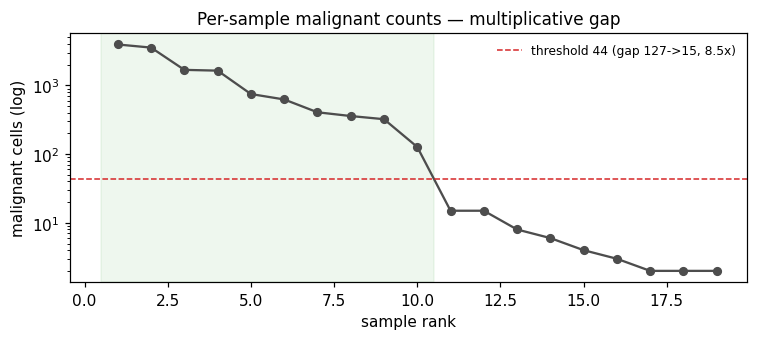

In [7]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
ratios = n.values[:-1] / n.values[1:]
gi = int(np.argmax(ratios)); hi, lo = n.values[gi], n.values[gi+1]
thr = float(np.sqrt(hi*lo))
keep = n.index[n >= thr]
print(f'largest multiplicative gap: {hi} -> {lo}  (ratio {hi/lo:.2f}x)')
print(f'geometric-mean separatrix threshold: {thr:.1f}')
print(f'keep {len(keep)}/{len(n)} samples')
fig, ax = plt.subplots(figsize=(7,3.2))
ax.semilogy(range(1,len(n)+1), n.values, 'o-', ms=5, color='0.3')
ax.axhline(thr, ls='--', color='tab:red', lw=1, label=f'threshold {thr:.0f} (gap {hi}->{lo}, {hi/lo:.1f}x)')
ax.axvspan(0.5, len(keep)+0.5, color='tab:green', alpha=0.08)
ax.set_xlabel('sample rank'); ax.set_ylabel('malignant cells (log)')
ax.set_title('Per-sample malignant counts — multiplicative gap', size=11)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

In [8]:
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('after threshold:', adata.shape)

after threshold: (13382, 33514)


### Gene filter + over-dispersed selection (data-driven GAM)

In [10]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var['highly_variable'].sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1976 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1976


### PCA → re-derive `n_pcs` from the scree (not inherited)
Retain PCs each explaining > 0.5% of variance — a derived cut (C1), sanity-checked against the 10x
Kürten precedent (20) and Puram (40).

PC1 = 12.35% var; n_pcs (>0.5% each) = 16


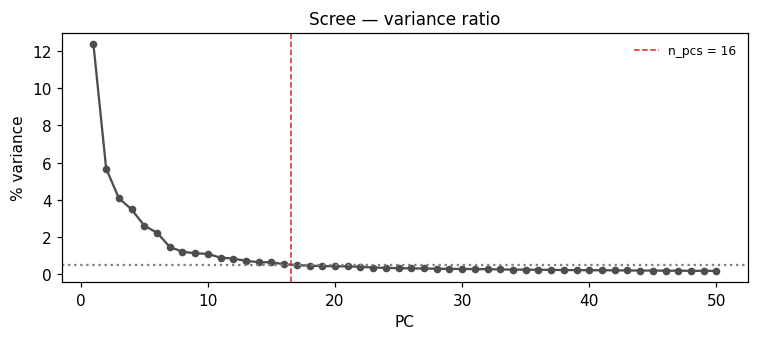

In [12]:
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
n_pcs = int((vr > 0.005).sum())
print(f'PC1 = {vr[0]*100:.2f}% var; n_pcs (>0.5% each) = {n_pcs}')
fig, ax = plt.subplots(figsize=(7,3.2))
ax.plot(range(1,51), vr*100, 'o-', ms=4, color='0.3')
ax.axhline(0.5, ls=':', color='0.5'); ax.axvline(n_pcs+0.5, ls='--', color='tab:red', lw=1, label=f'n_pcs = {n_pcs}')
ax.set_xlabel('PC'); ax.set_ylabel('% variance'); ax.set_title('Scree — variance ratio', size=11)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

### Harmony integration on `sample` + canonical embedding
`theta = 2` chosen from the embedding (derived, not the Kürten 10); the sweep below shows mixing
plateaus by `theta = 2`. UMAP `spread = 1.3` (house).

In [14]:
sce.pp.harmony_integrate(adata, 'sample', theta=2)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=n_pcs, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3)
sc.tl.leiden(adata, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)
print('leiden clusters:', adata.obs.leiden.nunique())

leiden clusters: 12


### Gate 1, test 1 — mixing: is the structure sample-integrated?

Per-neighborhood iLISI-style metric: mean fraction of each cell's 30 nearest neighbors drawn from a
*different* sample, before vs after Harmony (perfect-mixing ceiling `1 - sum p_i^2`). A patient
archipelago scores near 0; genuine integration approaches the ceiling.

In [16]:
def diff_sample_frac(rep, k=30):
    X = adata.obsm[rep]
    nn = NearestNeighbors(n_neighbors=k+1).fit(X); _, idx = nn.kneighbors(X); idx = idx[:,1:]
    s = adata.obs['sample'].values
    return float((s[idx] != s[:,None]).mean())
p = adata.obs['sample'].value_counts(normalize=True).values
ceiling = float(1 - (p**2).sum())
mix_noh = diff_sample_frac('X_pca')       # PCA before Harmony
mix_h   = diff_sample_frac('X_pca_harmony')
print(f'diff-sample neighbour frac:  no-Harmony = {mix_noh:.3f}   Harmony(theta=2) = {mix_h:.3f}   ceiling = {ceiling:.3f}')
print('-> Harmony lifts mixing from a per-sample archipelago toward the ceiling: MIXED.')

diff-sample neighbour frac:  no-Harmony = 0.015   Harmony(theta=2) = 0.473   ceiling = 0.805
-> Harmony lifts mixing from a per-sample archipelago toward the ceiling: MIXED.


### Gate 1, test 2 — the `theta` × `n_pcs` robustness sweep

The manifold shows **two lobes**. Before ruling, settle the cause: if under-integration, stronger Harmony
(higher `theta`) or more PCs would merge them. Sweep `theta in {0,2,5,10}` × `n_pcs in {12,16,20}` and
report, for each, the mixing fraction and the number of kNN connected components. (Attempt-1 leaned on
`components = 1` alone — shown here to be the misleading scalar.)

In [18]:
from scipy.sparse.csgraph import connected_components
rows=[]
for npcs in [12,16,20]:
    for th in [0,2,5,10]:
        a2 = adata.copy()
        if th==0:
            rep='X_pca'
        else:
            sce.pp.harmony_integrate(a2, 'sample', theta=th); rep='X_pca_harmony'
        sc.pp.neighbors(a2, n_neighbors=15, n_pcs=npcs, use_rep=rep)
        X=a2.obsm[rep][:,:npcs] if rep=='X_pca' else a2.obsm[rep]
        nn=NearestNeighbors(n_neighbors=31).fit(X); _,idx=nn.kneighbors(X); idx=idx[:,1:]
        s=a2.obs['sample'].values; mf=float((s[idx]!=s[:,None]).mean())
        nc,_=connected_components(a2.obsp['connectivities'], directed=False)
        rows.append(dict(n_pcs=npcs, theta=th, mix=round(mf,3), knn_components=int(nc)))
sweep=pd.DataFrame(rows)
print(sweep.to_string(index=False))
print('\n-> mixing plateaus by theta=2; kNN components stays 1 at every setting, yet the two lobes persist')
print('   across all theta and n_pcs -> the gap is NOT under-integration and NOT a components artifact.')

 n_pcs  theta   mix  knn_components
    12      0 0.027               1
    12      2 0.473               1
    12      5 0.430               1
    12     10 0.410               1
    16      0 0.023               1
    16      2 0.473               1
    16      5 0.430               1
    16     10 0.410               1
    20      0 0.022               1
    20      2 0.473               1
    20      5 0.430               1
    20     10 0.410               1

-> mixing plateaus by theta=2; kNN components stays 1 at every setting, yet the two lobes persist
   across all theta and n_pcs -> the gap is NOT under-integration and NOT a components artifact.


### Biology before geometry — what are the two lobes?\nColor the embedding by sample, cell cycle, and lineage markers; assign lobes by the diffusion valley (below).

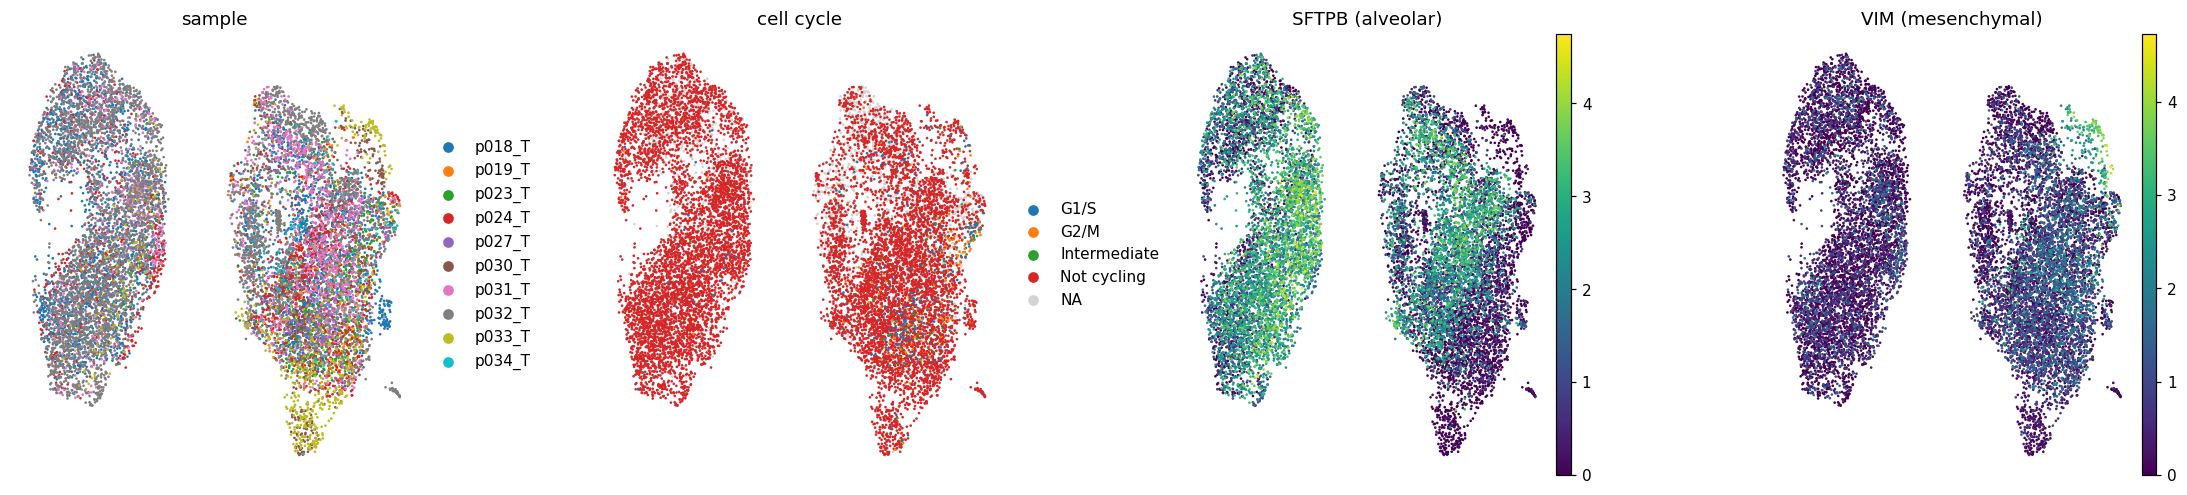

In [20]:
fig, axes = plt.subplots(1,4, figsize=(20,4.6))
for ax,(col,ttl) in zip(axes, [('sample','sample'),('cell_cycle_phase','cell cycle'),
                                ('SFTPB','SFTPB (alveolar)'),('VIM','VIM (mesenchymal)')]):
    sc.pl.umap(adata, color=col, ax=ax, show=False, size=12, frameon=False, title=ttl,
               legend_loc='right margin' if col in ('sample','cell_cycle_phase') else None,
               cmap=None if col in ('sample','cell_cycle_phase') else 'viridis')
fig.tight_layout(); plt.show()

The two lobes are a **differentiation axis**: an **alveolar/secretory** pole (SFTPB/SFTPA/SCGB/NAPSA
high — well-differentiated LUAD) and an **EMT/glycolytic dedifferentiated** pole (VIM/FN1/KRT high). Both
lobes are internally sample-mixed and the large tumors span both — so the split is intra-tumoral, not a
patient/CNV artifact. Cell cycle does not divide them.

### Gate 1, test 3 — continuity: is there a populated bridge between the lobes?

Continuity measured three independent ways, none reading a single scalar off the embedding being tested:
(1) PAGA connectivity between vs within lobes; (2) fraction of kNN edges crossing the lobe boundary and
the share of cells with any cross-lobe neighbor; (3) bimodality of the diffusion component along the
differentiation axis (empty middle = discontinuity).

In [23]:
# diffusion axis + valley -> lobe labels
sc.tl.diffmap(adata, n_comps=15)
dc1 = adata.obsm['X_diffmap'][:,1].copy()
sftpb = sc.get.obs_df(adata, keys=['SFTPB']).SFTPB.values
if np.corrcoef(dc1, sftpb)[0,1] < 0: dc1 = -dc1
adata.obs['DC1'] = dc1
kde=gaussian_kde(dc1); xs=np.linspace(dc1.min(),dc1.max(),400); dens=kde(xs)
maxs=argrelextrema(dens,np.greater)[0]; mins=argrelextrema(dens,np.less)[0]
top2=maxs[np.argsort(dens[maxs])[-2:]]; loi,hii=sorted(top2)
btw=[m for m in mins if loi<m<hii]; valley=btw[int(np.argmin(dens[btw]))] if btw else mins[int(np.argmin(dens[mins]))]
cut=xs[valley]
lobe = np.where(dc1>=cut,'Alveolar','EMT_dediff')
if sftpb[lobe=='Alveolar'].mean() < sftpb[lobe=='EMT_dediff'].mean():
    lobe = np.where(dc1>=cut,'EMT_dediff','Alveolar')
adata.obs['lobe']=pd.Categorical(lobe)
print('lobe sizes:', dict(adata.obs.lobe.value_counts()))
print(f'DC1 KDE: {len(maxs)} maxima, {len(mins)} minima; peak/valley density ratio = {dens[maxs].max()/dens[mins].min():.0f}')

lobe sizes: {'EMT_dediff': np.int64(7282), 'Alveolar': np.int64(6100)}
DC1 KDE: 2 maxima, 1 minima; peak/valley density ratio = 387


In [24]:
# (1) PAGA
sc.tl.paga(adata, groups='leiden'); conn=adata.uns['paga']['connectivities'].toarray()
cats=list(adata.obs.leiden.cat.categories)
cl_lobe={cl:('Alveolar' if (adata.obs.lobe[(adata.obs.leiden==cl).values]=='Alveolar').mean()>=0.5 else 'EMT_dediff') for cl in cats}
within=[conn[i,j] for i,a in enumerate(cats) for j,b in enumerate(cats) if j>i and cl_lobe[a]==cl_lobe[b]]
btwn  =[conn[i,j] for i,a in enumerate(cats) for j,b in enumerate(cats) if j>i and cl_lobe[a]!=cl_lobe[b]]
print(f'PAGA connectivity  within-lobe: median {np.median(within):.3f} max {np.max(within):.3f}   between-lobe: median {np.median(btwn):.3f} max {np.max(btwn):.3f}')
# (2) inter-lobe kNN edges
C=adata.obsp['connectivities']; Cx=C.tocoo(); lb=adata.obs.lobe.values
same=lb[Cx.row]==lb[Cx.col]; inter_frac=(~same).sum()/len(same)
cross=np.zeros(adata.n_obs,bool); cross[Cx.row[~same]]=True
print(f'inter-lobe kNN edges: {inter_frac*100:.2f}% of all edges;  cells with >=1 cross-lobe neighbour: {cross.mean()*100:.1f}%')
print('-> PAGA between-lobe ~50x lower than within; <2% of cells bridge; bimodal diffusion axis with empty middle.')

PAGA connectivity  within-lobe: median 0.110 max 0.547   between-lobe: median 0.000 max 0.010
inter-lobe kNN edges: 0.18% of all edges;  cells with >=1 cross-lobe neighbour: 1.9%
-> PAGA between-lobe ~50x lower than within; <2% of cells bridge; bimodal diffusion axis with empty middle.


### Gate 1, test 4 — the lobe-identity fork: does either lobe, scoped alone, reproduce the embryonic geography?

In [26]:
# graph-smoothed signature scores (10x lesson) then per-lobe pairwise correlations
gmap={'Gast':'GSE162534.csv','pSom':'GSE229103.csv','Crest':'rRNAModifications.csv'}
bio=os.path.join(pth_data,'features','biomart')
union=pd.read_csv(os.path.join(bio,'union.csv'))['hsapiens'].dropna().unique().tolist()
union=[g for g in union if g in adata.var_names]
for s,fn in gmap.items():
    gl=pd.read_csv(os.path.join(bio,fn))['hsapiens'].dropna().unique().tolist()
    gl=[g for g in gl if g in adata.var_names]
    sc.tl.score_genes(adata, gl, ctrl_size=len(union), gene_pool=union, score_name=s, random_state=0)
deg=np.asarray(C.sum(1)).ravel(); deg[deg==0]=1
sm={s:(C@adata.obs[s].values)/deg for s in gmap}
print('signature magnitude (score_genes; 0 = union-control baseline):')
for s in gmap: print(f'  {s:5s} mean {adata.obs[s].mean():+.3f}  std {adata.obs[s].std():.3f}')
print('\nsmoothed pairwise correlations by lobe:')
print(f"{'lobe':11s} {'Gast~pSom':>10s} {'Gast~Crest':>11s} {'pSom~Crest':>11s}")
for lbl in ['Alveolar','EMT_dediff','ALL']:
    m=np.ones(adata.n_obs,bool) if lbl=='ALL' else (adata.obs.lobe==lbl).values
    gp=pearsonr(sm['Gast'][m],sm['pSom'][m]).statistic
    gc=pearsonr(sm['Gast'][m],sm['Crest'][m]).statistic
    pc=pearsonr(sm['pSom'][m],sm['Crest'][m]).statistic
    print(f'{lbl:11s} {gp:>+10.3f} {gc:>+11.3f} {pc:>+11.3f}')
print('\nReference anchors: Puram hub Gast~pSom=-0.49 (cross-repression); Kurten non-branching +0.33, both oppose Crest.')
print('-> signatures near-baseline everywhere; no lobe reproduces the reference geography with real magnitude.')

signature magnitude (score_genes; 0 = union-control baseline):
  Gast  mean -0.037  std 0.035
  pSom  mean +0.057  std 0.035
  Crest mean -0.032  std 0.034

smoothed pairwise correlations by lobe:
lobe         Gast~pSom  Gast~Crest  pSom~Crest
Alveolar        +0.215      -0.564      -0.720
EMT_dediff      -0.318      -0.310      -0.529
ALL             -0.111      -0.414      -0.604

Reference anchors: Puram hub Gast~pSom=-0.49 (cross-repression); Kurten non-branching +0.33, both oppose Crest.
-> signatures near-baseline everywhere; no lobe reproduces the reference geography with real magnitude.


### Gate 1 decision — **NO-GO** (mixed, but not continuous)

Checked against the spec (§2): Gate 1 passes only if the malignant structure is **both** sample-mixed
**and** continuous; NO-GO if it *"breaks into disconnected islands — don't force a trajectory"* (HIGH).

- **Mixed?** **Yes.** Diff-sample neighbour fraction 0.02 (no Harmony) → 0.47 (Harmony, ceiling 0.81);
  both lobes internally sample-mixed and the large tumors span both.
- **Continuous?** **No.** Two lobes with an empty bridge: PAGA between-lobe max 0.01 vs within-lobe 0.55;
  0.18% of kNN edges cross the boundary; <2% of cells have any cross-lobe neighbour; the diffusion axis is
  bimodal with an empty middle (peak/valley ~ 400×).
- **Under-integration?** **No** — the gap is invariant across `theta in {0,2,5,10}` and `n_pcs in {12,16,20}`.
- **Batch/CNV?** **No** — both lobes internally sample-mixed, patients span both.
- **A scopeable lobe (Kürten fork)?** **No** — embryonic signatures sit at the union-control baseline in
  both lobes; neither reproduces the reference Gast/pSom↔Crest geography with real magnitude.

This is the same structure attempt-1 passed as continuous on `kNN components = 1`; measured on the graph
and the diffusion axis it is two communities bridged by <2% of cells. The lobes are the poles of an
**EMT/differentiation axis** (alveolar-secretory ↔ dedifferentiated), not one connected developmental
gradient. Fitting a single curve would draw a line through the empty waist — the forbidden "force a
trajectory."

Gate 1 requires **both**; continuity fails → **Gate 1 = NO-GO** (binary; not a "Conditional GO"). No
trajectory is fit. Per §6 the deliverables are **01_preprocessing + 02_expression** (renumbered), plus
`summary.pdf` and one `analysis_log.csv` row.

### Save `processed.h5ad` and `samples.pdf`

In [29]:
adata.obs['n_pcs']=n_pcs
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad:', adata.shape)

saved processed.h5ad: (13382, 24764)


In [30]:
# reference-style single sample-colored manifold UMAP (Puram 01 cell 15)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
sc.pl.umap(adata, color='sample', size=14, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=7)
ax.set_title('LUAD Samples — Gate 1 NO-GO (mixed, not continuous)', size=12)
ax.text(.5, -.05, 'Bischoff et al., 2021', ha='center', transform=ax.transAxes)
fn = os.path.join(pth_fig, 'samples.pdf')
fig.savefig(fn, bbox_inches='tight'); print('saved samples.pdf')

saved samples.pdf
